# Car Price Prediction - Exploratory Data Analysis

This notebook is a guided walk through the data. All logic lives in `src/` so the notebook and the training pipeline cannot drift apart.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src import config
from src.data_preprocessing import (load_raw_data, clean_data, is_two_wheeler,
                                    train_test_split_stratified, iqr_outlier_summary)
from src.eda import build_eda_frame, run_eda
pd.set_option('display.width', 120)

## 1. Load and inspect the raw data

In [2]:
raw = load_raw_data()
print(raw.shape)
raw.head()

(301, 9)


,Car_Name,Selling_Price,Year,Present_Price,Kms_Driven,Owner,Fuel_Type,Seller_Type,Transmission
0,ritz,3.35,2014,5.59,27000,0,Petrol,Dealer,Manual
1,sx4,4.75,2013,9.54,43000,0,Diesel,Dealer,Manual
2,ciaz,7.25,2017,9.85,6900,0,Petrol,Dealer,Manual
3,wagon r,2.85,2011,4.15,5200,0,Petrol,Dealer,Manual
4,swift,4.60,2014,6.87,42450,0,Diesel,Dealer,Manual


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    string 
 1   Selling_Price  301 non-null    float64
 2   Year           301 non-null    int64  
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Owner          301 non-null    int64  
 6   Fuel_Type      301 non-null    string 
 7   Seller_Type    301 non-null    string 
 8   Transmission   301 non-null    string 
dtypes: float64(2), int64(3), string(4)
memory usage: 30.0 KB


In [4]:
print('Missing values per column:')
print(raw.isna().sum())
print('\nExact duplicate rows:', raw.duplicated().sum())

Missing values per column:
Car_Name         0
Selling_Price    0
Year             0
Present_Price    0
Kms_Driven       0
Owner            0
Fuel_Type        0
Seller_Type      0
Transmission     0
dtype: int64

Exact duplicate rows: 2


In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Present_Price,301.0,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0


## 2. Data-quality finding: the file mixes cars and two-wheelers

`Car_Name` reveals motorcycles and scooters (Bajaj, Royal Enfield, Activa, ...). They form one contiguous block of rows, i.e. a second dataset appended to the cars.

In [6]:
bikes = is_two_wheeler(raw['Car_Name'])
print('two-wheeler rows:', bikes.sum(), '| index range:', raw.index[bikes].min(), '-', raw.index[bikes].max())
raw.loc[bikes, ['Car_Name', 'Present_Price', 'Selling_Price', 'Kms_Driven']].head(8)

two-wheeler rows: 101 | index range: 100 - 200


,Car_Name,Present_Price,Selling_Price,Kms_Driven
100,Royal Enfield Thunder 500,1.90,1.75,3000
101,UM Renegade Mojave,1.82,1.70,1400
102,KTM RC200,1.78,1.65,4000
103,Bajaj Dominar 400,1.60,1.45,1200
104,Royal Enfield Classic 350,1.47,1.35,4100
105,KTM RC390,2.37,1.35,21700
106,Hyosung GT250R,3.45,1.35,16500
107,Royal Enfield Thunder 350,1.50,1.25,15000


In [7]:
clean, report = clean_data(raw)
report

CleaningReport(rows_in=301, duplicates_removed=2, two_wheelers_removed=101, rows_out=198, notes=[])

After scoping to cars, the extreme 500,000 km value (an Activa scooter) is gone and `Seller_Type` becomes very imbalanced - individual sellers were mostly bike listings.

In [8]:
for col in ['Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']:
    print(clean[col].value_counts().to_dict())

{'Petrol': 138, 'Diesel': 58, 'CNG': 2}
{'Dealer': 193, 'Individual': 5}
{'Manual': 168, 'Automatic': 30}
{0: 193, 1: 4, 3: 1}


## 3. Train/test split first, then explore the training set only

In [9]:
X_train, X_test, y_train, y_test = train_test_split_stratified(clean)
print(len(X_train), 'train rows /', len(X_test), 'test rows')
eda = build_eda_frame(X_train, y_train)
pd.DataFrame(iqr_outlier_summary(eda, ['Selling_Price', 'Present_Price', 'Kms_Driven', 'Car_Age']))

158

 train rows / 40 test rows


,Selling_Price,Present_Price,Kms_Driven,Car_Age
lower_bound,-2.21875,-3.48125,-26655.0,-0.5
upper_bound,13.33125,23.84875,101345.0,11.5
n_outliers,13.00000,9.00000,3.0,6.0
max_value,35.00000,92.60000,142000.0,16.0


## 4. Figures

`run_eda()` writes every figure to `artifacts/figures/`.

In [10]:
summary = run_eda()
summary['spearman_with_target_train']

{'Present_Price': 0.712,
 'Kms_Driven': -0.281,
 'Car_Age': -0.533,
 'Kms_Per_Year': 0.168,
 'Owner': -0.139}

price_distribution.png


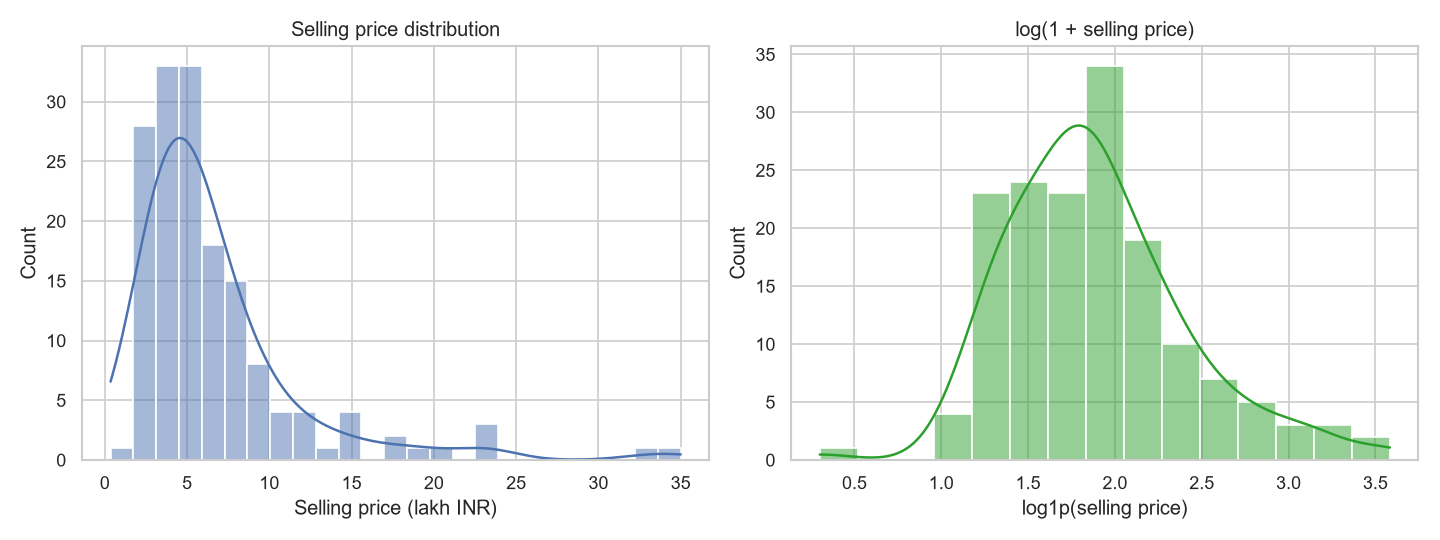

age_vs_price.png


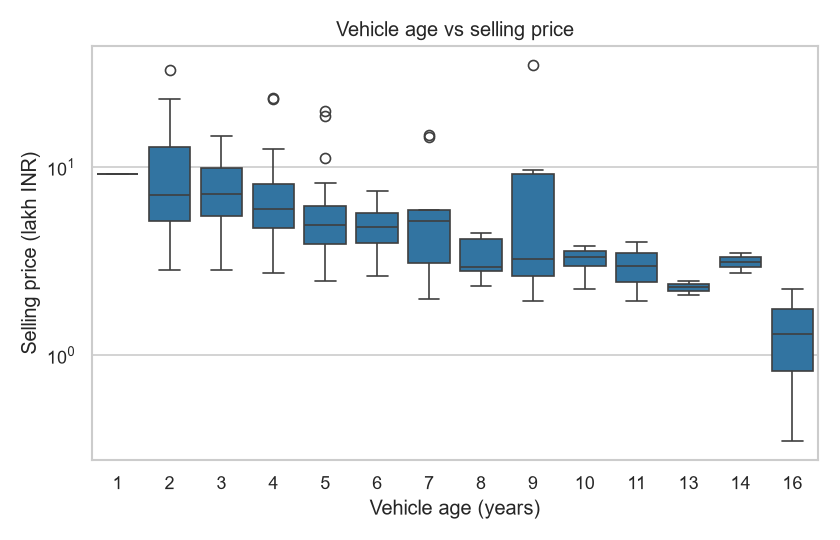

kms_vs_price.png


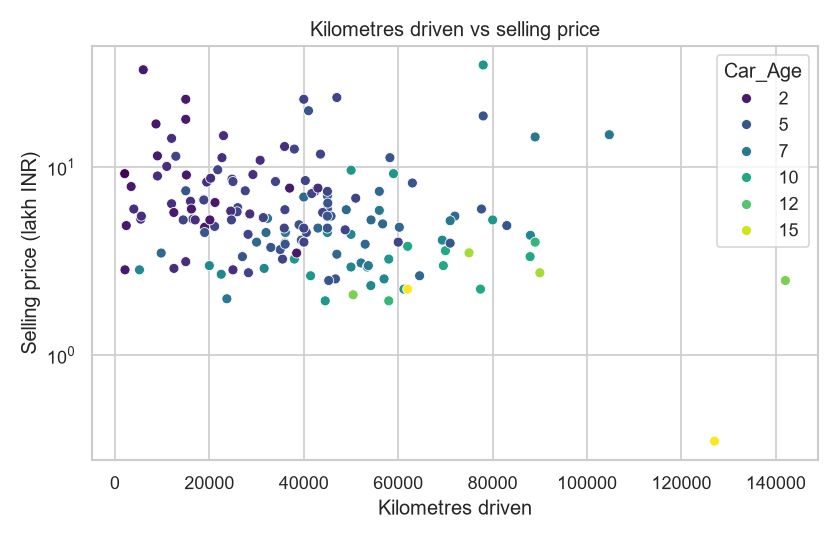

present_vs_selling_price.png


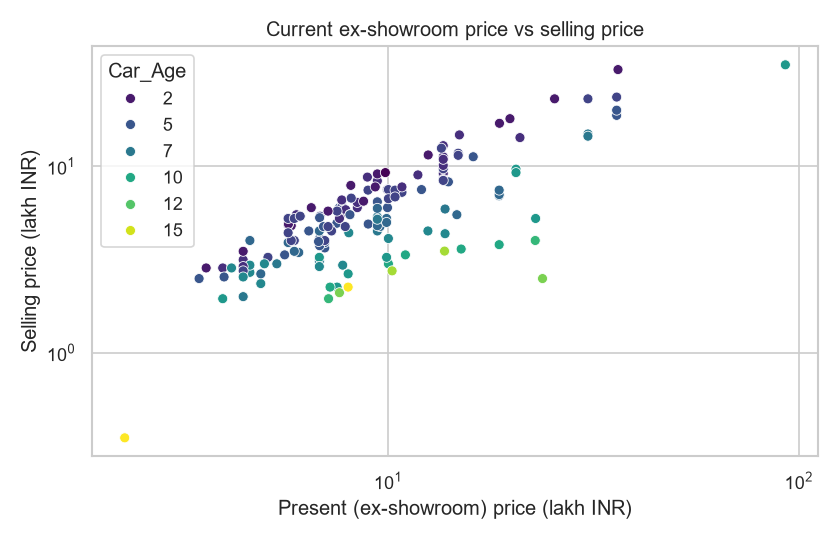

fuel_type_distribution.png


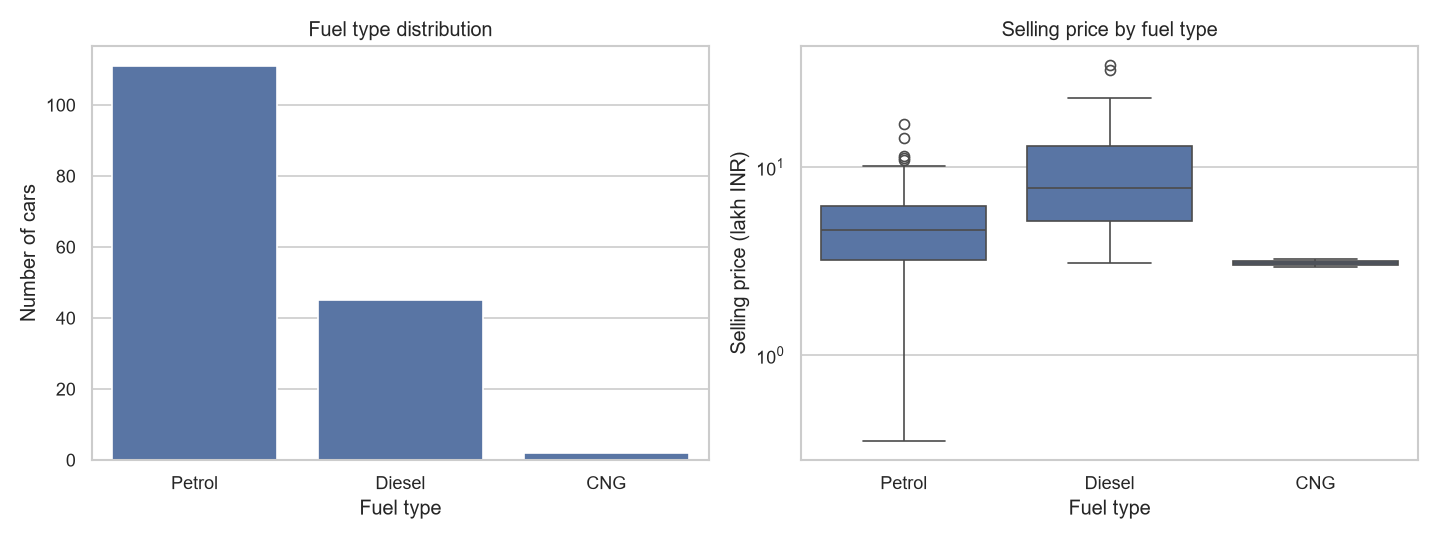

transmission_comparison.png


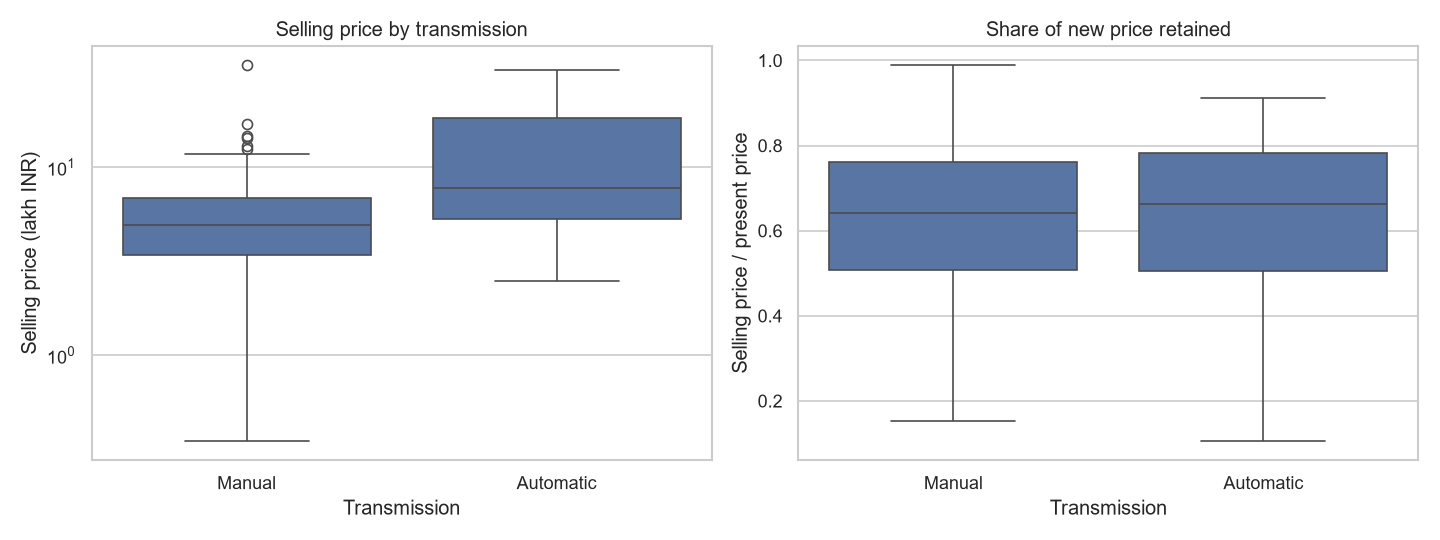

correlation_heatmap.png


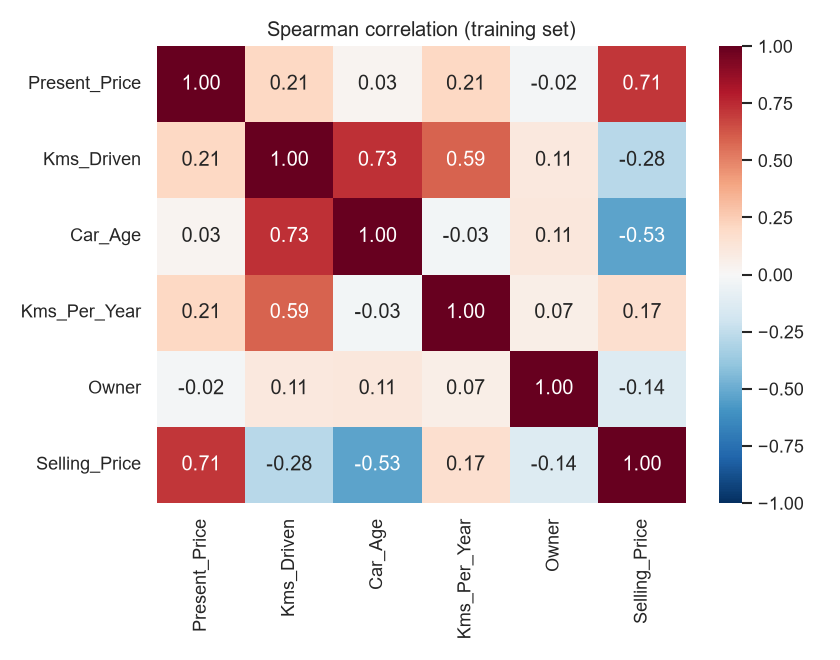

In [11]:
for name in summary['figures']:
    print(name)
    display(Image(filename=str(config.FIGURES_DIR / name)))

## 5. Takeaways that shaped the model

* Price is right-skewed and spans two orders of magnitude -> evaluate log and ratio targets.
* `Present_Price` is the strongest single signal; age is the second.
* Retained value (selling / present price) is similar for manual and automatic cars, so the automatic premium mostly reflects more expensive models.
* The single 92.6-lakh car is far outside the rest of the data; tree models cannot extrapolate to it on an absolute price scale, which motivated the ratio target.